# Topic 4 Lab — Data Quality and Responsible Data Practices — UniGuide AI

**Project:** UniGuide AI — AI-Powered University FAQ Assistant for UTM undergraduates

**Input (Topic 3 hand-off):** `chunks.pkl` + `prepared_chunks.jsonl` (260 chunks from seven 2026 UTM PDFs: S01, S02, S05, S06, S07, S08, S09), derived from `prepared_text_version1.3.jsonl`

**Source information:** `docs/week3_data_inventory_version1.3.md`; requirements: `docs/week2_requirements_version1.3.md`; evaluation criteria: `docs/week2_evaluation_criteria_version1.1.md`

**Outputs:** `prepared_chunks_clean.jsonl`, `chunks_clean.pkl`, `week4_data_quality_report.md`, `week4_validation_failures.csv`, `week4_duplicate_review.csv`, `week4_coverage_by_source.png`

**No API key is needed.** This notebook validates and governs data; embeddings, retrieval and model calls come later.

Cells follow the lab steps A0–A5, B1–B4 and C2.

## A0 — Plan the data quality gate

Start from what must be true about the data for a requirement to succeed, then choose the check.

| Topic 2 requirement | Required data / evidence | Quality concern | Observable check | Possible decision |
|---|---|---|---|---|
| **RAI2** — show source dates, mark undated sources "currency not verified", flag past deadlines (and criterion 7, time-sensitive handling) | Every source has a document date and its basis; time-bound schedules (S06 Semester I, S09 Semester II) carry `valid_until` and together reach the end of the 2026/2027 session (3 Oct 2027) | **Timeliness** + **Completeness** | Rule R4 (date and currency fields present), rule R5 (not past `valid_until`), dimension check on `doc_date_basis` and the latest `valid_until` | Accept / Review / Hold |
| **FR3 / RAI1** — answers carry a citation the student can verify | Every chunk keeps `source`, `source_url`, `pdf_page`, `section` and text that matches its PDF page | **Completeness** + **Accuracy** | Rules R1 (source and text present), R6 (section label present), R2 and R7 (no corrupted text), token recall of each chunk against its PDF page | Accept / Repair / Quarantine |
| **Criterion 7 / FR1** — handle two disagreeing sources and the two semesters correctly | Rule text from S02, dates from S01/S06/S09, and a semester label that separates near-identical S06 and S09 rows | **Consistency** + **Uniqueness** | Cross-source comparison (credit-load approver, Federal Territory Day), near-duplicate check between S06 and S09 | Review / precedence rule |

### Cell 0 — Build the Topic 3 hand-off files

In [1]:
# Cell 0 — Build chunks.pkl and prepared_chunks.jsonl from the Topic 3 output (only if they do not exist yet)
!pip install -q langchain-core pandera pandas matplotlib pypdf

import json, os, pickle
from langchain_core.documents import Document

SRC = "/content/prepared_text_version1.3.jsonl"     # change if your path differs
os.makedirs("/content/data", exist_ok=True); os.makedirs("/content/docs", exist_ok=True)

if os.path.exists("/content/chunks.pkl") and os.path.exists("/content/prepared_chunks.jsonl"):
    print("Hand-off files already present: nothing to build.")
else:
    records = [json.loads(l) for l in open(SRC, encoding="utf-8") if l.strip()]
    built = []
    for r in records:
        meta = {k: v for k, v in r.items() if k != "text"}   # keep all Topic 3 metadata
        meta["page"] = r["pdf_page"]                          # the lab code reads metadata['page'] and ['source']
        built.append(Document(page_content=r["text"], metadata=meta))
    with open("/content/chunks.pkl", "wb") as f:
        pickle.dump(built, f)
    with open("/content/prepared_chunks.jsonl", "w", encoding="utf-8", newline="\n") as f:
        for i, c in enumerate(built):
            f.write(json.dumps({"chunk_id": i, "text": c.page_content, "metadata": c.metadata}, ensure_ascii=False) + "\n")
    print(f"Built {len(built)} chunks.")

Built 260 chunks.


## A1 — Load and verify the Topic 3 hand-off

In [2]:
# Cell 1 — Topic 4 setup and Topic 3 hand-off verification
!pip install -q pandera pandas matplotlib langchain-core

import os, re, json, pickle, hashlib

import pandas as pd

import matplotlib
import matplotlib.pyplot as plt

import pandera.pandas as pa

with open('/content/chunks.pkl', 'rb') as f:
    chunks = pickle.load(f)

prepared_records = []

with open('/content/prepared_chunks.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            prepared_records.append(json.loads(line))

print(f'Compatibility chunks: {len(chunks)}')

print(f'Inspectable JSONL records: {len(prepared_records)}')

if len(chunks) != len(prepared_records):
    raise ValueError('Topic 3 hand-off mismatch: JSONL and PKL chunk counts differ.')

# extra check: the two files hold the same text in the same order
assert all(c.page_content == r['text'] for c, r in zip(chunks, prepared_records)), 'PKL and JSONL text differ'

print('Topic 3 hand-off verified.')

print(chunks[0].page_content[:250])

print(chunks[0].metadata)

Compatibility chunks: 260
Inspectable JSONL records: 260
Topic 3 hand-off verified.
International Undergraduate and
Postgraduate Students:
21 - 24 September 2026 (UTM JB)
26 & 27 September 2026 (UTM KL)
Local Undergraduate Students:
4 October 2026 (UTM JB & UTM KL)
Local Postgraduate Students:
14 -18 September 2026 (UTM JB)
26 & 27 
{'record_id': 'S01-p001-01', 'source_id': 'S01', 'source': 'utm_academic_calendar_2026_2027_1.pdf', 'source_sha256': '7cfd417f62a1041c608794fb0f72235da4412c9c43239d603cc90e2f8d30a492', 'source_type': 'dates', 'source_url': 'https://amd.utm.my/wp-content/uploads/sites/460/2026/05/Final_Kalendar-Akademik-Sarjana-Muda.Sarjana.Kedoktoran-20262027-14.5.2026-pembetulan.pdf', 'retrieved_date': '2026-11-20', 'edition': 'Academic Calendar 2026/2027, Bachelor/Master/Doctoral (English, 1 page)', 'doc_date': '2026-11-20', 'doc_date_basis': "file name 'utm_academic_calendar_2026_2027_1' (session 2026/2027); no publication date printed", 'valid_until': '2027-10-03', 'cur

## A2 — Quality inventory for missing, corrupted and noisy data

Lab Cell 2, extended with project fields that Topic 3 actually captured (`record_id`, `source_id`, `section`, `doc_date`, `currency_status`, `valid_until`, `extraction_method`). Nothing new was invented.

In [3]:
# Cell 2 — Build a chunk-quality inventory
rows = []

for i, chunk in enumerate(chunks):
    text = chunk.page_content or ''
    meta = chunk.metadata or {}
    source = str(meta.get('source', '') or '')
    stripped = text.strip()

    rows.append({
        'chunk_id': i,
        'record_id': meta.get('record_id'),
        'source_id': meta.get('source_id'),
        'source': source,
        'page': meta.get('page', None),
        'text': text,
        'char_count': len(stripped),
        'missing_text': len(stripped) == 0,
        'missing_source': source.strip() == '',
        'corrupted_char': ('\x00' in text) or ('�' in text),
        'noisy_whitespace': bool(re.search(r'\n{4,}| {4,}', text)),
        # project-specific fields (all captured in Topic 3)
        'section': meta.get('section'),
        'doc_date': meta.get('doc_date'),
        'currency_status': meta.get('currency_status'),
        'valid_until': meta.get('valid_until'),
        'source_type': meta.get('source_type'),
        'extraction_method': meta.get('extraction_method'),
    })

df = pd.DataFrame(rows)

# project-specific checks
df['private_use_glyph'] = df['text'].str.contains('[\ue000-\uf8ff]', regex=True)   # symbol-font glyph codes left by PDF extraction
df['missing_section'] = df['section'].fillna('').astype(str).str.strip().eq('')     # Pandera skips nulls, so test as a boolean column
df['front_matter'] = df['source_id'].eq('S02') & (df['page'] <= 12)                 # S02 PDF pages 1-12: cover, copyright, contents, contributors (checked by hand in A3)

print(df[['chunk_id','source','page','char_count',
          'missing_text','missing_source',
          'corrupted_char','noisy_whitespace']].head())

print(df['char_count'].describe())

print('Missing text:', int(df['missing_text'].sum()))
print('Missing source metadata:', int(df['missing_source'].sum()))
print('Possible corrupted text:', int(df['corrupted_char'].sum()))
print('Possible noisy whitespace:', int(df['noisy_whitespace'].sum()))
print('Private-use symbol glyphs:', int(df['private_use_glyph'].sum()))
print('Missing section label:', int(df['missing_section'].sum()))
print('Front matter (S02 pdf page <= 12):', int(df['front_matter'].sum()))

print('\nChunks, characters and missing section label by source:')
print(df.groupby('source_id').agg(chunks=('chunk_id','size'), chars=('char_count','sum'),
                                  min_chars=('char_count','min'), missing_section=('missing_section','sum')))

   chunk_id                                 source  page  char_count  \
0         0  utm_academic_calendar_2026_2027_1.pdf     1         554   
1         1  utm_academic_calendar_2026_2027_1.pdf     1        1044   
2         2  utm_academic_calendar_2026_2027_1.pdf     1         382   
3         3  utm_academic_calendar_2026_2027_1.pdf     1         886   
4         4  utm_academic_calendar_2026_2027_1.pdf     1         438   

   missing_text  missing_source  corrupted_char  noisy_whitespace  
0         False           False           False             False  
1         False           False           False             False  
2         False           False           False             False  
3         False           False           False             False  
4         False           False           False             False  
count     260.00000
mean      472.65000
std       258.16212
min        11.00000
25%       246.00000
50%       502.00000
75%       726.00000
max      1044.00000

### A2b — Five-dimension evidence for the scorecard

This cell measures the five operational dimensions on the whole corpus. It reads only the chunk metadata, plus the original PDFs when they are available (accuracy check). Each row is an observation with its evidence; the decision is a first reading, confirmed or changed in A5 and the report.

In [15]:
# Cell 2b — Five operational quality dimensions (evidence for report Section 1)
# Manual verification against the PDF page images (done by the author, 2026-11-26)
MANUAL_CHECKED = ['S09-p001-04','S09-p002-04','S06-p002-01','S07-p001-02','S08-p001-02',   # five spot-check chunks: correct
                  'S08-p001-06','S08-p002-01',                                              # infographic steps Q6, Q7: correct
                  'S02-p069-01','S02-p069-02','S05-p008-01','S05-p009-01']                  # corrected below
import collections, itertools, datetime as dt
from pathlib import Path

today = dt.date.today()
metas = [c.metadata for c in chunks]
texts = [c.page_content for c in chunks]
rid   = [m['record_id'] for m in metas]
sid   = [m['source_id'] for m in metas]
dim_rows = []
def add(dim, finding, evidence, impact, decision):
    dim_rows.append({'Dimension': dim, 'Finding': finding, 'Evidence': evidence, 'Impact': impact, 'Decision': decision})
def norm_ws(s): return ' '.join(s.split())
def snip(text, pat, w=70):
    t = norm_ws(text); m = re.search(pat, t, re.I)
    return None if not m else '...' + t[max(0, m.start()-w): m.end()+w] + '...'
def find(pat, ids=None):
    return [(rid[i], snip(texts[i], pat)) for i in range(len(texts)) if (ids is None or sid[i] in ids) and re.search(pat, texts[i], re.I)]

# ---------- 1. COMPLETENESS
REQ = ['record_id','source_id','source','pdf_page','section','doc_date','currency_status','source_url','retrieved_date']
miss = {f: collections.Counter(sid[i] for i, m in enumerate(metas) if m.get(f) in (None, '')) for f in REQ}
miss = {f: dict(v) for f, v in miss.items() if v}
miss_other = {f: v for f, v in miss.items() if f != 'section'}
add('Completeness', 'Required citation and currency fields are present in every chunk: record_id, source_id, source, pdf_page, doc_date, currency_status, source_url and retrieved_date.',
    f'Fields checked: {[f for f in REQ if f != "section"]}; chunks with an empty value: {miss_other or "none"} (of {len(df)} chunks).',
    'Every answer can cite its file, page and source date, and the user can open the original.', 'Pass' if not miss_other else 'Review')
add('Completeness', 'The `section` label is empty where the source has no headings (S05) or the page is front matter (S02).',
    f'Empty `section` by source: {miss.get("section", "none")}. Total chunks without a section label: {int(df.missing_section.sum())} of {len(df)} ({100*df.missing_section.mean():.1f}%).',
    'A chunk without a section label gives a weaker citation locator (page only).', 'Review' if miss else 'Pass')
no_printed = collections.Counter(sid[i] for i, m in enumerate(metas) if m.get('printed_page') in (None, ''))
add('Completeness', '`printed_page` is empty for sources that print no page numbers (S01, S05-S09 use rows, Q numbers or slides) and for S02 front matter (roman page numbers).',
    f'Chunks without printed_page by source: {dict(no_printed)}', 'Not a defect: those chunks are cited by row, question or PDF page.', 'Pass')
need = {'credit limit': r'credit load|credits per semester', 'registration steps': r'register|registration',
        'matric card': r'matric card', 'UTMID': r'UTMID', 'deadline / penalty': r'penalt|deadline|late',
        'graduation': r'graduat', 'withdrawal / deferment': r'withdraw|deferment',
        'academic calendar dates': r'semester [i]+\b.*20\d\d|20\d\d'}
cov = {k: sorted({sid[i] for i in range(len(texts)) if re.search(p, texts[i], re.I)}) for k, p in need.items()}
gap = [k for k, v in cov.items() if not v]
chars = collections.Counter(); [chars.update({sid[i]: len(texts[i])}) for i in range(len(texts))]
tot = sum(chars.values())
add('Completeness', f'Every project topic has at least one source (topics with none: {gap or "none"}); coverage is uneven, and S02 holds most of the text.',
    f'Sources mentioning each topic: {cov}. Share of characters: ' + str({k: f"{100*v/tot:.1f}%" for k, v in sorted(chars.items())}),
    'A topic found only in one source depends on that source being right; services other than matric card and UTMID are not covered at all.', 'Warning')
img = [rid[i] for i, m in enumerate(metas) if m.get('extraction_method') != 'pypdf']
add('Completeness', 'Image-only content is recovered only in three places (OCR or manual transcription); other images are not indexed.',
    f'Records with non-pypdf extraction: {img}. Not OCR\'d on purpose (personal data): S05 p3, p8.',
    'Answers that depend on other screenshots or infographics have no source and must use the fallback.', 'Warning')

# ---------- 2. CONSISTENCY
ft = find(r'Federal Territory Day', {'S01', 'S06'})
add('Consistency', 'The two date sources disagree on Federal Territory Day (S06: 1 January 2027, S01: 1 February 2027).',
    str(ft), 'The date a student receives depends on which chunk is retrieved; the precedence rule (calendar decides dates) or both sources must be shown.', 'Review')
cr = find(r'(approv|approve)[^.]{0,140}(Dean|Deputy Dean|Academic Advisor)|(Dean|Deputy Dean|Academic Advisor)[^.]{0,140}(approv|more than 18|exceed)', {'S02', 'S06'})
cr = [x for x in cr if x[1] and re.search(r'18|credit', x[1], re.I)]
add('Consistency', 'The approver for more than 18 credits differs: the regulations (S02) name the Dean; the work schedule (S06) names the Academic Advisor and the Deputy Dean.',
    str(cr[:4]) or 'no matching passage: check regex', 'Two authorities in one answer; rules come from S02, the route and dates from S06 (precedence rule).', 'Review')
sec_hdr = collections.defaultdict(set)
for i, m in enumerate(metas):
    if sid[i] == 'S02':
        for x in re.finditer(r'Section\s+(\d+)', norm_ws(texts[i])): sec_hdr[rid[i]].add(x.group(0))
mism = [(rid[i], metas[i].get('section'), sorted(sec_hdr[rid[i]])) for i in range(len(texts))
        if sid[i] == 'S02' and sec_hdr[rid[i]] and metas[i].get('section') not in sec_hdr[rid[i]]]
add('Consistency', '`section` comes from the page header, while the text cites other sections. Most are ordinary cross-references; S02 p36 is a known case where the header may be wrong.',
    f'{len(mism)} S02 chunks mention a Section number different from their header. Examples (record, header, cited): {mism[:4]}',
    'A citation could point to the wrong section if the header is wrong.', 'Review' if mism else 'Pass')
HEADER_RE = re.compile(r'^\s*Academic Regulations[ \t]*\n')   # running page header left at the start of a chunk
run_hdr = [rid[i] for i in range(len(texts)) if sid[i] == 'S02' and HEADER_RE.match(texts[i])]
left_after = [rid[i] for i in range(len(texts)) if sid[i] == 'S02' and HEADER_RE.match(HEADER_RE.sub('', texts[i], count=1))]
add('Consistency', 'The running page header "Academic Regulations" was left at the start of S02 chunks (noise from the PDF layout). The rule that removes it is applied in cell 5b; after it, no chunk starts with the header (checked again in cell 7).',
    f'{len(run_hdr)} of {sum(1 for x in sid if x == "S02")} S02 chunks start with the header, e.g. {run_hdr[:4]}; still starting with it after the rule: {left_after or "none"}',
    'Two extra words in the chunk; low harm for retrieval, but it shows the footer/header remover did not catch every layout line.', 'Pass' if not left_after else 'Warning')
fmt = {s: sorted({re.sub(r'\d', '9', str(m.get('doc_date'))) for i, m in enumerate(metas) if sid[i] == s}) for s in sorted(set(sid))}
typo = find(r'Janaury')
s09 = [x for x in find(r'January 2026|Semester I, 2026/2027', {'S09'})]
add('Consistency', 'Labels and dates are inconsistent inside sources: date formats differ (S02 gives a year only), S06 has a spelling error in a date, and S09 (Semester II) contains Semester I text copied from the older schedule.',
    f'doc_date patterns: {fmt}. Typo: {typo}. S09 passages: {s09}', 'Exact-match search can miss "Janaury"; a Semester II question could retrieve wrong-semester wording.', 'Warning')

# ---------- 3. ACCURACY
RAW = Path('/content/')
def tokens(s): return re.sub(r'[^a-z0-9]+', ' ', s.lower()).split()
acc_done = False
if RAW.exists() and any(RAW.glob('*.pdf')):
    from pypdf import PdfReader
    import logging; logging.getLogger('pypdf').setLevel(logging.ERROR)
    pdfs = {m['source']: RAW / m['source'] for m in metas if (RAW / m['source']).exists()}
    pages = {}
    recalls, low = [], []
    for i, m in enumerate(metas):
        if m.get('extraction_method') != 'pypdf' or m['source'] not in pdfs: continue
        if m['source'] not in pages: pages[m['source']] = [p.extract_text() or '' for p in PdfReader(str(pdfs[m['source']])).pages]
        pt = collections.Counter(tokens(pages[m['source']][m['pdf_page'] - 1])); ct = collections.Counter(tokens(texts[i]))
        n = sum(ct.values()); hit = sum(min(c, pt[t]) for t, c in ct.items()); r = hit / n if n else 1.0
        recalls.append(r)
        if r < 0.98: low.append((rid[i], round(r, 3)))
    acc_done = True
    # checked by hand: pypdf splits a capital letter from the rest of the word ("T otal", "V ertical", "T eknologi"); the Topic 3 whitespace normaliser joins them
    EXPLAINED = {'S02-p008-02': '"V ertical" repaired to "Vertical"', 'S02-p026-02': '"T otal" repaired to "Total" (3 times)', 'S02-p063-02': '"T eknologi" repaired to "Teknologi"'}
    unexplained = [x for x in low if x[0] not in EXPLAINED]
    add('Accuracy', 'Text fidelity: every pypdf chunk\'s words can be found on its own PDF page, so preparation did not add or change content (three chunks differ only by a repaired kerning split).',
        f'{len(recalls)} chunks checked against the original PDFs; minimum token recall {min(recalls):.3f}; below 0.98: {low or "none"}; explained by hand: { {k: v for k, v in EXPLAINED.items() if k in dict(low)} }; unexplained: {unexplained or "none"}',
        'Low recall would mean text was altered by a fix-up or merged from another page. Text fidelity is not the same as the PDF being correct.', 'Pass' if not unexplained else 'Review')
if not acc_done:
    add('Accuracy', 'Text fidelity against the original PDFs was NOT checked because the raw PDFs are not in this runtime (`/content/week3_project/data/raw`).',
        'N.V. — Not Verified', 'Upload the seven PDFs to that folder and re-run this cell.', 'N.V.')
ocr = [(rid[i], metas[i].get('ocr_token_recall'), metas[i].get('extraction_method')) for i in range(len(metas)) if metas[i].get('extraction_method') != 'pypdf']
ocr_checked = all(o[0] in MANUAL_CHECKED for o in ocr)
add('Accuracy', 'OCR-supplemented text (S05 legend, S08 Q6 and Q7) was compared with the page images by the author on 2026-11-26: S08 Q6 and Q7 steps are correct; the S05 legend label "PTF" was wrong and is corrected to "FTF" in cell 5b. OCR alone recovered only 71-88% of the words, so the check by eye is what supports this text.',
    str(ocr), 'Wrong or missing legend terms or steps would give wrong answers with a citation; the manual check removes that risk for these three records.', 'Pass' if ocr_checked else 'Review')
import random; random.seed(4)
cand = [i for i in range(len(metas)) if sid[i] in ('S01', 'S06', 'S07', 'S08', 'S09')]
pick = random.sample(cand, 5)
spot_checked = all(rid[i] in MANUAL_CHECKED for i in pick)
add('Accuracy', 'Manual spot-check of five random chunks (S06, S07, S08, S09) against the PDF page images, done by the author on 2026-11-26: all five match.' if spot_checked else 'Manual spot-check list: compare these five random chunks with the PDF page images. Automatic recall cannot detect a value moved to the wrong row.',
    '; '.join(f'{rid[i]} (p{metas[i]["pdf_page"]}): {norm_ws(texts[i])[:90]}...' for i in pick),
    'Automatic recall cannot detect a value moved to the wrong row; the page-image check does. It covers five chunks, not the whole corpus.' if spot_checked else 'Accuracy against the real document, not only against the extracted text, is not verified until this is done.', 'Pass' if spot_checked else 'Review')

# ---------- 4. TIMELINESS
per_src = {}
for i, m in enumerate(metas): per_src.setdefault(sid[i], m)
fresh = [(s, m['doc_date'], m['doc_date_basis'], m.get('valid_until'), m['currency_status'],
          'EXPIRED' if m.get('valid_until') and dt.date.fromisoformat(m['valid_until']) < today else 'ok') for s, m in sorted(per_src.items())]
MONTHS = 'January|February|March|April|May|June|July|August|September|October|November|December'
sched = {}
for s in ('S06', 'S09'):
    txt = ' '.join(texts[i] for i in range(len(texts)) if sid[i] == s)
    ds = []
    for d, mo, y in re.findall(rf'(\d{{1,2}})\s+({MONTHS})\s+(20\d\d)', txt):
        ds.append(dt.datetime.strptime(f'{d} {mo} {y}', '%d %B %Y').date())
    sched[s] = {'dates': len(ds), 'already_past': sum(d < today for d in ds), 'first': min(ds).isoformat() if ds else None, 'last': max(ds).isoformat() if ds else None}
tb = sorted({sid[i] for i in range(len(sid)) if 'time_bound' in str(metas[i]['currency_status'])})
SESSION_END = dt.date(2027, 10, 3)
reach = max(dt.date.fromisoformat(per_src[s]['valid_until']) for s in tb if per_src[s].get('valid_until'))
expired = [f[0] for f in fresh if f[-1] == 'EXPIRED']
add('Timeliness', 'Requirement (RAI2): every source has a document date, and the time-bound schedules S06 and S09 are unexpired and together reach the end of the 2026/2027 session.',
    f'Run date {today}. (source, doc_date, basis, valid_until, currency, status): {fresh}. Time-bound: {tb}; expired: {expired or "none"}; latest valid_until {reach} vs session end {SESSION_END}. '
    f'Dates in each schedule: {sched}. Past dates in a schedule are normal and are not a defect.',
    'After 3 Oct 2027 both schedules are outdated; the assistant must flag past deadlines and must name the semester.', 'Pass' if (not expired and reach >= SESSION_END) else 'Warning')
lab_ok = all(per_src[s].get('doc_date') and per_src[s].get('doc_date_basis') and per_src[s].get('retrieved_date') and per_src[s].get('currency_status') for s in per_src)
add('Timeliness', 'Every source has a document date, a stated basis, a retrieval date and a currency label. S05 is labelled current on the author\'s confirmation, and S01 has no printed publication date (its basis says so).',
    str([(s, per_src[s]['doc_date_basis'], per_src[s]['currency_status']) for s in ('S01', 'S05')]),
    'If either document is outdated, the assistant would give old rules with a current label; the label is at least traceable to its basis.', 'Pass' if lab_ok else 'Review')
proxy = {s: per_src[s]['doc_date_basis'] for s in ('S01', 'S05', 'S09', 'S02')}
add('Timeliness', 'Three of seven document dates are proxies, not printed publication dates: S01 (file name gives the session only), S05 (PDF creation date) and S09 (PDF creation date; the PDF prints only "September 2026"). S02 prints a year only. The author confirmed that S01, S05 and S09 were published in 2026; the exact day is not confirmed.',
    str(proxy), 'The year is confirmed, but the exact day is not; "current" is shown on the year and the semester only.', 'Warning')

# ---------- 5. UNIQUENESS
dupid = [k for k, n in collections.Counter(rid).items() if n > 1]
th = collections.defaultdict(list)
for i in range(len(texts)): th[hashlib.sha256(norm_ws(texts[i].strip()).encode()).hexdigest()].append(rid[i])
dupt = [v for v in th.values() if len(v) > 1]
fh = collections.defaultdict(set)
for i, m in enumerate(metas): fh[m['source_sha256']].add(sid[i])
dupf = [sorted(v) for v in fh.values() if len(v) > 1]
add('Uniqueness', 'No duplicate record IDs, identical chunk texts or identical source files.',
    f'duplicate IDs: {dupid or "none"}; identical normalised texts: {dupt or "none"}; identical files: {dupf or "none"}',
    'Exact duplicates would over-weight one passage in retrieval.', 'Pass' if not (dupid or dupt or dupf) else 'Review')
def sh5(t):
    w = tokens(t); return {' '.join(w[j:j+5]) for j in range(max(1, len(w) - 4))}
cand = [i for i in range(len(texts)) if len(texts[i]) > 150]
S = {i: sh5(texts[i]) for i in cand}
near = []
for a, b in itertools.combinations(cand, 2):
    j = len(S[a] & S[b]) / len(S[a] | S[b])
    if j >= 0.5: near.append((rid[a], rid[b], round(j, 2)))
nolabel = {s: sum(1 for i in range(len(texts)) if sid[i] == s and not re.search(r'Semester\s+(I|II)\b', texts[i])) for s in ('S06', 'S09')}
add('Uniqueness', 'Near-duplicate chunks (5-word overlap >= 0.5) appear between S06 (Semester I) and S09 (Semester II): same row layout and wording, different dates. Not an error.',
    f'{len(near)} pairs, e.g. {near[:6] or "none"}. Chunks whose text does not say which semester: {nolabel} of 22 each (the semester is only in the source file name and metadata).',
    'A question like "when is the late registration penalty?" can retrieve both semesters, so the answer must name the semester. Compare before removing anything.', 'Review' if near else 'Pass')

dims = pd.DataFrame(dim_rows)
pd.set_option('display.max_colwidth', 600, 'display.width', 250)
for dim, g in dims.groupby('Dimension', sort=False):
    print('=' * 100, '\n', dim.upper())
    for _, x in g.iterrows():
        print(f"- Finding : {x['Finding']}\n  Evidence: {x['Evidence']}\n  Impact  : {x['Impact']}\n  Decision: {x['Decision']}\n")
print('Decision counts:', {k: int(v) for k, v in dims['Decision'].value_counts().items()})
print('\nDecisions by dimension:')
print(pd.crosstab(dims['Dimension'], dims['Decision']).reindex(['Completeness','Consistency','Accuracy','Timeliness','Uniqueness']))
NEAR_PAIRS = near

 COMPLETENESS
- Finding : Required citation and currency fields are present in every chunk: record_id, source_id, source, pdf_page, doc_date, currency_status, source_url and retrieved_date.
  Evidence: Fields checked: ['record_id', 'source_id', 'source', 'pdf_page', 'doc_date', 'currency_status', 'source_url', 'retrieved_date']; chunks with an empty value: none (of 260 chunks).
  Impact  : Every answer can cite its file, page and source date, and the user can open the original.
  Decision: Pass

- Finding : The `section` label is empty where the source has no headings (S05) or the page is front matter (S02).
  Evidence: Empty `section` by source: {'S02': 24, 'S05': 10}. Total chunks without a section label: 34 of 260 (13.1%).
  Impact  : A chunk without a section label gives a weaker citation locator (page only).
  Decision: Review

- Finding : `printed_page` is empty for sources that print no page numbers (S01, S05-S09 use rows, Q numbers or slides) and for S02 front matter (roman pag

## A3 — Manual inspection (lab sample, random_state=42)

In [5]:
# Cell 3 — Manual inspection
sample = df.sample(min(10, len(df)), random_state=42)

for idx in sample['chunk_id']:
    c = chunks[int(idx)]
    print('\nCHUNK', idx, '| record', c.metadata.get('record_id'))
    print('Source:', c.metadata.get('source','?'), '| Page:', c.metadata.get('page','?'))
    print(c.page_content[:1200])


CHUNK 30 | record S02-p020-02
Source: utm_academic_regulations.pdf | Page: 20
“Minimum Credits” refers to the credits registered, which amount to
twelve (12) credits, including Audit Status (HS) and Compulsory Attendance
(HW) courses in a semester, except for KS students and/ or a student in their
final two (2) semesters of study. “Course” refers to a subject within the program curriculum that has its own
code. “Practical Course” refers to a course conducted in laboratories, workshops,
studios, fieldwork, and industrial/practical training. “Digital Badge” refers to a form of digital certification awarded to
participants who have passed a Micro-credential course. “Residency” refers to a minimum period during which a registered student
is present (physically or non-physically) at the University.

CHUNK 181 | record S02-p078-01
Source: utm_academic_regulations.pdf | Page: 78
(2) The faculty will prepare the name list of eligible graduating students
for approval by the Senate Standing Com

### A3 observations (recorded after reading the ten sample chunks and the neighbouring records)

| # | Observation | Classification / quality concern | Evidence needed | Decision |
|---|---|---|---|---|
| 1 | Chunk 9 (`S02-p006-01`) is a table of contents: "SECTION 3 REGISTRATION AND STUDIES 11 … Article 3. Programme Registration 11-13 …". | Noise: a navigation index, not policy content (relevance / completeness) | Compare with PDF page 6; confirm that S02 pages 4–12 are cover, copyright, contents and contributors | Quarantine (rule R8, decided in A5) |
| 2 | Chunk 223 (`S09-p001-04`): "4 Course registration (with penalty) 2 days 1 23 - 24 March 2027 Penalty of RM100.00 …". The text never says "Semester II"; the same row in S06 differs only in the dates. | Uniqueness + consistency risk: near-duplicate across semesters | Compare `S06-p001-04`; check that the metadata carries the source file and the semester | Retain; the answer must name the semester (criterion 7) |
| 3 | Chunk 211 (`S06-p002-06`) prints "22 Janaury 2026 Thaipusam" (spelling error, and the year 2026 inside a 2026/2027 schedule) and "1 January 2027 Federal Territory Day" (S01 gives 1 February 2027). | Inconsistent: typo and a conflicting date | S06 page 2 image; S01 | Retain verbatim and flag; precedence rule: the calendar decides dates |
| 4 | Chunks 173 and 177 (`S02-p075-03`, `S02-p076-03`) are lists of invigilator duties that start in the middle of a list ("(xiii) …", "(ii) …"). Which role the duties belong to (chief invigilator or assistant invigilator) is only in the neighbouring chunk. | Context lost at a chunk boundary (completeness) | Read `S02-p075-02` and `S02-p076-02`; compare with the PDF pages | Retain; note for Topic 7 (overlap or neighbour retrieval) |
| 5 | Chunk 142 (`S02-p065-01`) starts with the running page header "Academic Regulations" (removed in cell 5b); chunk 181 (`S02-p078-01`) joins the end of Appendix 9 with the start of Appendix 10. | Noise (page header) and mixed topics in one chunk | PDF pages 65 and 78; count of chunks that start with the header (A2b) | Header removed in cell 5b; retain (appendix mix noted) |
| 6 | Chunk 258 (`S08-p001-06`) contains "[Text read from page image]" followed by four steps typed from an infographic. | Provenance: supplemented text (accuracy) | Compare with the infographic on page 1 | Checked by the author against the infographic: correct (cell 5b) |

🤔 **Reflection.** The issue that is hardest to express as a simple rule is observation 2 (and, in the same way, observation 4). `S09-p001-04` is not empty, is longer than 50 characters, has no corrupted characters and carries a valid date, so rules R1–R8 all pass. The problem is what the text does not say: the semester is missing from the text, and a twin chunk in S06 says almost the same thing with other dates. This touches **uniqueness** (near-duplicate across sources), **consistency** (two semesters in one retrieval result) and **completeness** (context lost at a boundary). An automated check looks at one chunk at a time; it would miss this because the chunk is valid on its own and the defect appears only when it is compared with its twin or with the document structure.

## A4 — Validation rules (Pandera)

Eight rules, each with the failure it detects and an action. R3 is a warning threshold, not a defect test. A rule that fails is evidence to review, not proof of bad data.

In [6]:
# Cell 4 — Repeatable validation rules
import datetime as dt
today_s = dt.date.today().isoformat()
def nonblank(s): return s.fillna('').astype(str).str.strip().str.len() > 0

schema = pa.DataFrameSchema({
    'chunk_id': pa.Column(int, checks=pa.Check.ge(0), nullable=False),
    # R1 missingness: source and text must exist (traceability for FR3/RAI1). Hard fail.
    'source': pa.Column(str, checks=pa.Check(nonblank, error='R1 source metadata must not be empty'), nullable=False),
    'text':   pa.Column(str, checks=pa.Check(nonblank, error='R1 chunk text must not be empty'), nullable=False),
    # R2 corruption: null bytes or replacement characters. Hard fail.
    'corrupted_char': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='R2 corrupted characters found')),
    # R3 threshold: very short chunks are a WARNING, not automatically a defect.
    'char_count': pa.Column(int, checks=pa.Check.ge(50, error='R3 chunk shorter than 50 characters (review)')),
    # R4 completeness of currency metadata (RAI2). Hard fail.
    'doc_date': pa.Column(str, checks=pa.Check(nonblank, error='R4 doc_date missing'), nullable=False),
    'currency_status': pa.Column(str, checks=pa.Check(nonblank, error='R4 currency_status missing'), nullable=False),
    # R5 timeliness: a time-bound source must not be past its valid_until (RAI2). Review.
    'valid_until': pa.Column(str, nullable=True, required=True, checks=pa.Check(
        lambda s: s.isna() | (s >= today_s), error='R5 source is past valid_until')),
    # R6 completeness of the citation locator: section label present. Review.
    'missing_section': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='R6 section label missing (citation locator)')),
    # R7 noise: private-use symbol glyphs (e.g. tick marks in a table). Review.
    'private_use_glyph': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='R7 private-use symbol glyph in text')),
    # R8 relevance: front matter (cover, copyright, contents, contributor names) is not policy content. Review / quarantine.
    'front_matter': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='R8 front matter, not policy content')),
}, strict=False)

try:
    schema.validate(df, lazy=True)
    failure_cases = pd.DataFrame(columns=['schema_context','column','check','check_number','failure_case','index'])
    print('All schema rules passed.')
except pa.errors.SchemaErrors as exc:
    failure_cases = exc.failure_cases.copy()
    print('Validation found failures.')

failure_cases = failure_cases.copy()
failure_cases['rule'] = failure_cases['check'].astype(str).str.extract(r'(R\d)')[0]
failure_cases['record_id'] = failure_cases['index'].map(df['record_id'])
failure_cases['source_id'] = failure_cases['index'].map(df['source_id'])

RULES = {
 'R1': ('Missing source or text', 'source != "" and text != ""', 'Untraceable or empty evidence', 'Hard fail'),
 'R2': ('Corrupted characters', 'no NUL or U+FFFD', 'Garbled extraction', 'Hard fail'),
 'R3': ('Minimum useful length', 'char_count >= 50', 'Page-number or heading fragments with no meaning', 'Warning'),
 'R4': ('Currency metadata present', 'doc_date and currency_status not empty', 'Cannot show source date (RAI2)', 'Hard fail'),
 'R5': ('Not past valid_until', 'valid_until empty or >= today', 'Expired time-bound source (RAI2)', 'Review'),
 'R6': ('Section label present', 'section not empty', 'Weak citation locator (FR3)', 'Review'),
 'R7': ('No private-use glyphs', 'no U+E000-U+F8FF', 'Symbols (tick marks) lost in table text', 'Review'),
 'R8': ('Not front matter', 'not S02 pdf page <= 12', 'Cover, copyright, contents and contributor names pollute retrieval', 'Review / quarantine'),
}
rule_rows = []
for r, (name, cond, why, action) in RULES.items():
    f = failure_cases[failure_cases['rule'] == r]
    n = f['index'].nunique()
    rule_rows.append({'Rule': r, 'Checks': name, 'Condition': cond, 'Failure detected': why, 'Failures': n,
                      'Percent of chunks': round(100 * n / len(df), 1),
                      'By source': dict(f.groupby('source_id')['index'].nunique()), 'Action': action,
                      'Examples': list(f['record_id'].drop_duplicates().head(3))})
rule_summary = pd.DataFrame(rule_rows)
pd.set_option('display.max_colwidth', 120, 'display.width', 250)
print(rule_summary.drop(columns=['Examples']).to_string(index=False))
print()
print(rule_summary[['Rule', 'Examples']].to_string(index=False))
print(f'\nTotal failure rows: {len(failure_cases)}; chunks with at least one failure: {failure_cases["index"].nunique()} of {len(df)}')

os.makedirs('/content/docs', exist_ok=True)
failure_cases.to_csv('/content/docs/week4_validation_failures.csv', index=False, encoding='utf-8-sig')
print('Saved /content/docs/week4_validation_failures.csv')

Validation found failures.
Rule                    Checks                              Condition                                                   Failure detected  Failures  Percent of chunks                      By source              Action
  R1    Missing source or text            source != "" and text != ""                                      Untraceable or empty evidence         0                0.0                             {}           Hard fail
  R2      Corrupted characters                       no NUL or U+FFFD                                                 Garbled extraction         0                0.0                             {}           Hard fail
  R3     Minimum useful length                       char_count >= 50                   Page-number or heading fragments with no meaning         7                2.7 {'S02': 5, 'S05': 1, 'S09': 1}             Warning
  R4 Currency metadata present doc_date and currency_status not empty                                    

### A4 results (from the run above)

| Rule | Condition | Why this rule? / failure being detected | Failures | Decision |
|---|---|---|---|---|
| R1 Text and source present | `text != ""` and `source != ""` | Empty chunks give no evidence; a missing source cannot be cited (FR3, RAI1) | 0 | Hard fail |
| R2 No corrupted characters | no NUL byte or U+FFFD | Garbled PDF extraction would give wrong answers | 0 | Hard fail |
| R3 Minimum useful length | `char_count >= 50` | Detects page-number or heading fragments. 50 characters is about eight words; it is an illustrative warning level, not a defect test (a valid schedule row can be shorter, e.g. S09 row 19 has 45) | 7 (2.7%): S02 5, S05 1, S09 1 | Warning, then review each case |
| R4 Currency metadata present | `doc_date` and `currency_status` not empty | RAI2 needs a source date to display | 0 | Hard fail |
| R5 Not past `valid_until` | `valid_until` empty or on/after today | An expired time-bound source must not be treated as current (S06 runs to 2027-03-21, S01 and S09 to 2027-10-03) | 0 | Review |
| R6 Section label present | `section` not empty | A chunk without a section gives only a page number as citation locator | 34 (13.1%): S02 24, S05 10 | Review |
| R7 No private-use glyphs | no characters U+E000 to U+F8FF | Symbol-font characters (tick marks in a table) lose their meaning in text | 2 (0.8%): `S02-p069-01`, `S02-p069-02` | Review |
| R8 Not front matter | not S02 PDF page 12 or earlier | Cover, copyright, contents and contributor names do not answer questions and pollute retrieval | 14 (5.4%): all S02 | Review, then quarantine |

The hard-fail rules (R1, R2 and R4) have **0 failures**, so the corpus passes its hard gates. In total 57 failure rows touch 38 of 260 chunks (14.6%); the rows are in `week4_validation_failures.csv`.

## A5 — Review and triage the failures

In [7]:
# Cell 4b — Look at the evidence before deciding
show = ['S02-p004-01','S02-p007-01','S02-p016-02','S02-p069-01','S02-p069-02','S02-p071-04','S05-p008-01','S09-p003-02','S02-p012-01']
by_id = {c.metadata['record_id']: c for c in chunks}
for r in show:
    c = by_id[r]
    print('\n##', r, '| section:', c.metadata.get('section'), '| chars:', len(c.page_content.strip()))
    print(c.page_content[:420])
print('\nNeighbours of the short chunks (previous and next record on the same page):')
ids = [c.metadata['record_id'] for c in chunks]
for r in ['S02-p016-02','S02-p071-04','S09-p003-02']:
    i = ids.index(r)
    print('\n--', r, 'follows', ids[i-1], ':', repr(chunks[i-1].page_content[-160:]))


## S02-p004-01 | section: None | chars: 24
www.penerbit.utm.my
2026

## S02-p007-01 | section: None | chars: 11
vi
Contents

## S02-p016-02 | section: None | chars: 37
MQF Malaysian Qualification Framework

## S02-p069-01 | section: Section 10 | chars: 789
Academic Regulations
Table 11 Horizontal Credit Transfer Methodology
Types
 of Application
Place of Study (Credit
Transfer Percentage/
Residency Period)
Grade Calculation in
GPA/CGPA
UTM Other IPT (Local/
Overseas)
Counted Not
Counted
Still in studies No limit No limit
Minimum residency
of one (1) semester"

Has been
awarded a
bachelor's degree
and is pursuing a
second bachelor's
degree
No limit Not exceeding 50%
(M

## S02-p069-02 | section: Section 10 | chars: 15
exceeding 60%


## S02-p071-04 | section: Section 10 | chars: 45
the eligibility course set by the University.

## S05-p008-01 | section: None | chars: 49
Click View Slip to view course registration slip9

## S09-p003-02 | section: Row 19 | chars: 45
19 Revision Period 

In [8]:
# Cell 4c — Triage table: rule, evidence checked, interpretation, decision, reason
TRIAGE = pd.DataFrame([
 # record_id, rule, evidence checked, interpretation, decision, reason
 ['S02-p004-01', 'R3, R8, R6', 'Chunk text and PDF page 4 (publisher cover page)', 'Defect for this use: publisher website and year only', 'Quarantine', 'No policy content; cannot answer a student question'],
 ['S02-p005-01..03', 'R8, R6', 'Chunk text (copyright and publisher details, English and Malay)', 'Defect for this use: copyright notice', 'Quarantine', 'No policy content; kept in the quarantine file for rights review (B4)'],
 ['S02-p006..p010 (8 chunks)', 'R8, R6', 'Chunk text: table of contents and list of tables with page numbers', 'Defect for this use: navigation index', 'Quarantine', 'Section titles and page numbers would match many queries but give no answer'],
 ['S02-p012-01..02', 'R8, R6', 'Chunk text: list of contributors (names of 40+ staff)', 'Defect + unnecessary personal data', 'Quarantine', 'Names are not needed for any requirement (B4)'],
 ['S02-p016-02', 'R3', 'Text and previous chunk (abbreviation list)', 'Valid short exception: the last abbreviation (MQF) split from its list', 'Retain', 'Legitimate glossary entry'],
 ['S02-p071-04', 'R3', 'Text and previous chunk (MOOC credit-transfer item (d))', 'Valid continuation: end of a sentence', 'Retain (flag)', 'Short, but part of the MOOC rule; flagged so retrieval can pull the previous chunk'],
 ['S09-p003-02', 'R3', 'Text and PDF page 3 (schedule row 19)', 'Valid short row: Revision Period, 5-11 July 2027', 'Retain', 'Legitimate schedule row with its date'],
 ['S02-p069-01, S02-p069-02', 'R7, R3', 'Text and PDF page 69 (Table 11, tick marks printed as a symbol font); author checked the page image', 'Defect in extraction: ticks lost. Page image: ticks in "Counted" for Still in studies and Mobility Program; "Not Counted" for all other rows', 'Retain, text supplemented', 'Note added to both chunks so the rule can be answered (see cell 5b)'],
 ['S05-p008-01', 'R3', 'Text ends "...registration slip9"; author checked slide 8', 'The trailing "9" is the step number, fused to the text', 'Retain, text corrected', 'Written as "(step 9)" (see cell 5b)'],
], columns=['Failed item', 'Rule triggered', 'Evidence checked', 'Interpretation', 'Decision', 'Reason'])
pd.set_option('display.max_colwidth', 90, 'display.width', 250)
print(TRIAGE.to_string(index=False))

# The decision applied to the corpus
QUARANTINE = sorted(df.loc[df['front_matter'], 'record_id'])
FLAGS = {
 'S02-p016-02': 'R3_short_valid_exception', 'S02-p071-04': 'R3_short_continuation', 'S09-p003-02': 'R3_short_valid_row',
}
for rec in df.loc[df['missing_section'] & ~df['front_matter'], 'record_id']:
    FLAGS.setdefault(rec, 'R6_no_section_label')
print('\nQuarantine:', len(QUARANTINE), 'chunks ->', sorted({q.split('-')[1] for q in QUARANTINE}))
print('Flagged but retained:', len(FLAGS), 'chunks')
assert all(q in by_id for q in QUARANTINE) and all(f in by_id for f in FLAGS)

              Failed item Rule triggered                                                                                    Evidence checked                                                                                                                               Interpretation                  Decision                                                                             Reason
              S02-p004-01     R3, R8, R6                                                    Chunk text and PDF page 4 (publisher cover page)                                                                                         Defect for this use: publisher website and year only                Quarantine                                No policy content; cannot answer a student question
          S02-p005-01..03         R8, R6                                     Chunk text (copyright and publisher details, English and Malay)                                                                              

**What the triage shows.** Seven chunks fail R3 (short text). Two (`S02-p004-01` cover page, `S02-p007-01` contents header) are front matter, and one (`S02-p069`) is a table fragment whose tick marks were lost; after the author checked the page image, a note was added ("Counted" for Still in studies and Mobility Program, "Not Counted" for the other rows). The other four are valid: an abbreviation entry, a sentence ending, a schedule row, and a trailing digit that the author confirmed is the slide's step number (text corrected to "(step 9)"). A hard-fail on length would have deleted correct content. Nothing was removed silently: 14 front-matter chunks are quarantined in `prepared_chunks_quarantine.jsonl` with a reason, and 22 retained chunks carry a `quality_flag` in their metadata.

⚠️ *Validation detects a condition. Engineering judgement determines the action.*

## B1 — Exact duplicates (provenance kept), then apply the A5 decisions

Exact hashing finds identical normalised text only. It does not prove semantic uniqueness, detect near-duplicates, or resolve contradictory versions. The lab's Cell 5 is used as written, except that the cleaned files are written in Cell 5b after the A5 decisions are applied, so the final corpus is written once.

In [9]:
# Cell 5 — Exact hash deduplication with provenance preserved
seen = {}
unique_chunks = []
duplicate_records = []

for chunk in chunks:
    normalized = re.sub(r'\s+', ' ', chunk.page_content.strip())
    h = hashlib.sha256(normalized.encode('utf-8')).hexdigest()

    if h not in seen:
        seen[h] = {'metadata': chunk.metadata.copy(), 'sources': [chunk.metadata.get('source','?')]}
        unique_chunks.append(chunk)
    else:
        seen[h]['sources'].append(chunk.metadata.get('source','?'))
        duplicate_records.append({
            'type': 'exact',
            'hash': h,
            'record_a': seen[h]['metadata'].get('record_id'),
            'record_b': chunk.metadata.get('record_id'),
            'duplicate_source': chunk.metadata.get('source','?'),
            'first_source': seen[h]['sources'][0],
            'preview': normalized[:160],
            'decision': 'Remove later copy, keep provenance',
            'reason': 'Identical normalised text',
        })

print('Before:', len(chunks))
print('After exact deduplication:', len(unique_chunks))
print('Exact duplicates found:', len(duplicate_records))

# Near-duplicates (S06 vs S09) are NOT removed: they are different semesters. Record them for review.
rid_to_chunk = {c.metadata['record_id']: c for c in chunks}
for a, b, j in NEAR_PAIRS:
    ca, cb = rid_to_chunk[a], rid_to_chunk[b]
    duplicate_records.append({
        'type': 'near_duplicate', 'hash': '', 'record_a': a, 'record_b': b,
        'duplicate_source': cb.metadata.get('source','?'), 'first_source': ca.metadata.get('source','?'),
        'preview': f'jaccard={j}; ' + re.sub(r'\s+', ' ', ca.page_content.strip())[:130],
        'decision': 'Retain both' if {ca.metadata['source_id'], cb.metadata['source_id']} == {'S06', 'S09'} else 'Review',
        'reason': 'Different semester schedules (Semester I vs Semester II) with different dates' if {ca.metadata['source_id'], cb.metadata['source_id']} == {'S06', 'S09'} else 'Check manually',
    })

os.makedirs('/content/docs', exist_ok=True)
os.makedirs('/content/data', exist_ok=True)
dup_df = pd.DataFrame(duplicate_records, columns=['type','hash','record_a','record_b','duplicate_source','first_source','preview','decision','reason'])
dup_df.to_csv('/content/docs/week4_duplicate_review.csv', index=False, encoding='utf-8-sig')
print('Near-duplicate pairs recorded for review:', int((dup_df['type'] == 'near_duplicate').sum()))
print('Saved /content/docs/week4_duplicate_review.csv')

Before: 260
After exact deduplication: 260
Exact duplicates found: 0
Near-duplicate pairs recorded for review: 7
Saved /content/docs/week4_duplicate_review.csv


In [10]:
# Cell 5b — Apply the A5 decisions and write the reviewed corpus (cleaned PKL + inspectable JSONL)
from langchain_core.documents import Document
import copy

# (MANUAL_CHECKED is defined in cell 2b, before the accuracy rows)
NOTE69 = "\n[Checked against PDF page 69, column 'Grade Calculation in GPA/CGPA': Counted = 'Still in studies' and 'Mobility Program'; Not Counted = second bachelor's degree, MOOC, MC, APEL.C and the combination of APEL, MOOC and MC.]"
TEXT_FIXES = {
    'S02-p069-01': ('The total combination not', 'The total combination not' + NOTE69),
    'S02-p069-02': ('exceeding 60%', 'exceeding 60%' + NOTE69),
    'S05-p008-01': ('registration slip9', 'registration slip (step 9)'),
    'S05-p009-01': ("PTF = Face-to-face final exam (printed as 'PTF' in the source; likely 'FTF', not verified).", 'FTF = Face-to-face final exam.'),
}
def sid_of(r): return r.split('-')[0]
clean_chunks, quarantined = [], []
for c in unique_chunks:
    rec = c.metadata['record_id']
    if rec in set(QUARANTINE):
        q = Document(page_content=c.page_content, metadata=copy.deepcopy(c.metadata))
        q.metadata['quality_decision'] = 'quarantine_front_matter'
        quarantined.append(q)
        continue
    meta = copy.deepcopy(c.metadata)
    meta['quality_review'] = 'topic4'
    text = c.page_content
    if sid_of(rec) == 'S02' and HEADER_RE.match(text):
        text = HEADER_RE.sub('', text, count=1)
        meta['header_removed'] = 'Academic Regulations'
    if rec in FLAGS:
        meta['quality_flag'] = FLAGS[rec]
    if rec in MANUAL_CHECKED:
        meta['manual_check'] = 'page image checked by author, 2026-11-26'
    if rec in TEXT_FIXES:
        old, new = TEXT_FIXES[rec]
        assert old in text, rec
        text = text.replace(old, new)
        meta['manual_fix'] = f'{old!r} -> {new!r}'
    clean_chunks.append(Document(page_content=text, metadata=meta))

print('Topic 3 chunks:', len(chunks), '| after exact dedup:', len(unique_chunks),
      '| quarantined:', len(quarantined), '| reviewed corpus:', len(clean_chunks))

with open('/content/data/chunks_clean.pkl', 'wb') as f:
    pickle.dump(clean_chunks, f)

def write_jsonl(path, docs):
    with open(path, 'w', encoding='utf-8', newline='\n') as f:
        for i, c in enumerate(docs):
            f.write(json.dumps({'chunk_id': i, 'text': c.page_content, 'metadata': c.metadata}, ensure_ascii=False) + '\n')

write_jsonl('/content/data/prepared_chunks_clean.jsonl', clean_chunks)
write_jsonl('/content/data/prepared_chunks_quarantine.jsonl', quarantined)
print('Saved cleaned PKL and inspectable JSONL outputs (plus the quarantine file, kept for review).')

Topic 3 chunks: 260 | after exact dedup: 260 | quarantined: 14 | reviewed corpus: 246
Saved cleaned PKL and inspectable JSONL outputs (plus the quarantine file, kept for review).


## B2 — Coverage against the application scope

Coverage is judged against what the application must answer, not against equal chunk counts. The grouping below uses `source_type`, which Topic 3 actually recorded (dates, rules, how_to, faq); it is real metadata, not a proxy.

| Required area | Why it must be covered | Expected evidence |
|---|---|---|
| Academic calendar dates, both semesters | FR1; criterion 7 | S01 plus S06 (Semester I) and S09 (Semester II) |
| Registration deadlines and penalties | FR1, RAI2 | S06 and S09 |
| Academic rules (credit load, repeating courses, fees, examinations) | FR1 | S02 |
| Registration steps | FR1 | S05 (with S06/S09 for dates) |
| Matric card services | FR1 | S07 |
| UTMID services | FR1 | S08 |

source  chunks  percent  characters  percent_chars source_type                                                                   file
   S02     169     68.7       96066           82.1       rules                                           utm_academic_regulations.pdf
   S09      22      8.9        4723            4.0       dates                                utm_ug_work_schedule_sem2_2026_2027.pdf
   S06      22      8.9        4840            4.1       dates                                     utm_ug_work_schedule_2026_2027.pdf
   S07      11      4.5        3472            3.0         faq                                           utm_matric_card_faq_2026.pdf
   S05      10      4.1        2529            2.2      how_to utm_User-Manual_Course-Registration-Senior-Student_update202620271.pdf
   S08       7      2.8        2067            1.8         faq                                                 utm_utmid_faq_2026.pdf
   S01       5      2.0        3304            2.8       dates

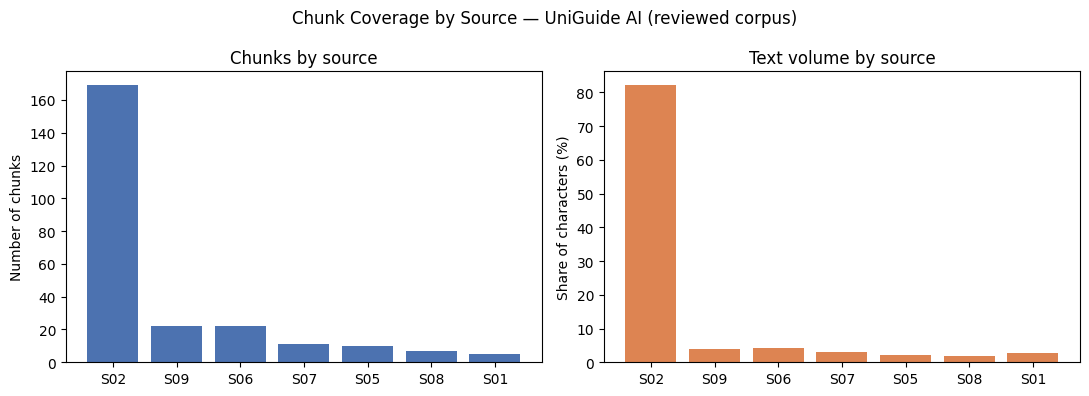


                                     Required area Expected evidence Actual evidence (chunks or sources)                                                                  Note
          Academic calendar dates, both semesters     S01, S06, S09    {'S01': 5, 'S06': 22, 'S09': 22} Both semesters present; S01 is a one-page table flattened to 5 chunks
             Registration deadlines and penalties          S06, S09                          [S06, S09]                                    Present in both semester schedules
Academic rules (credit load, repeat, fees, exams)               S02                        {'S02': 169}                                               Large body of rule text
                               Registration steps               S05                         {'S05': 10}             Only 10 chunks; screenshots not indexed except the legend
                             Matric card services               S07                         {'S07': 11}                         

In [11]:
# Cell 6 — Coverage by source
from collections import Counter

source_counts = Counter(c.metadata.get('source_id', 'unknown') for c in clean_chunks)
char_counts = Counter()
for c in clean_chunks: char_counts[c.metadata.get('source_id', 'unknown')] += len(c.page_content)
total_chars = sum(char_counts.values())

coverage = pd.DataFrame([
    {'source': src, 'chunks': cnt, 'percent': round(cnt / len(clean_chunks) * 100, 1),
     'characters': char_counts[src], 'percent_chars': round(char_counts[src] / total_chars * 100, 1),
     'source_type': next(c.metadata['source_type'] for c in clean_chunks if c.metadata['source_id'] == src),
     'file': next(c.metadata['source'] for c in clean_chunks if c.metadata['source_id'] == src)}
    for src, cnt in source_counts.items()
]).sort_values('chunks', ascending=False)
print(coverage.to_string(index=False))

by_type = coverage.groupby('source_type')[['chunks', 'characters']].sum()
by_type['percent_chunks'] = (100 * by_type['chunks'] / by_type['chunks'].sum()).round(1)
by_type['percent_chars'] = (100 * by_type['characters'] / by_type['characters'].sum()).round(1)
print('\nBy source type (actual metadata):')
print(by_type)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(coverage['source'].astype(str), coverage['chunks'], color='#4C72B0')
ax[0].set_ylabel('Number of chunks'); ax[0].set_title('Chunks by source')
ax[1].bar(coverage['source'].astype(str), coverage['percent_chars'], color='#DD8452')
ax[1].set_ylabel('Share of characters (%)'); ax[1].set_title('Text volume by source')
fig.suptitle('Chunk Coverage by Source — UniGuide AI (reviewed corpus)')
plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_source.png', dpi=150)
plt.show()

# Required areas: expected vs actual evidence in the reviewed corpus
def n_src(sources): return {s: source_counts.get(s, 0) for s in sources}
def has(sources, pat): return sorted({c.metadata['source_id'] for c in clean_chunks if c.metadata['source_id'] in sources and re.search(pat, c.page_content, re.I)})
area_rows = [
 ['Academic calendar dates, both semesters', 'S01, S06, S09', n_src(['S01','S06','S09']), 'Both semesters present; S01 is a one-page table flattened to 5 chunks'],
 ['Registration deadlines and penalties', 'S06, S09', has(['S06','S09'], r'penalt|late|deadline'), 'Present in both semester schedules'],
 ['Academic rules (credit load, repeat, fees, exams)', 'S02', n_src(['S02']), 'Large body of rule text'],
 ['Registration steps', 'S05', n_src(['S05']), 'Only 10 chunks; screenshots not indexed except the legend'],
 ['Matric card services', 'S07', n_src(['S07']), '11 Q&A chunks'],
 ['UTMID services', 'S08', n_src(['S08']), '7 Q&A chunks; Q6 and Q7 from images'],
]
areas = pd.DataFrame(area_rows, columns=['Required area', 'Expected evidence', 'Actual evidence (chunks or sources)', 'Note'])
pd.set_option('display.max_colwidth', 110, 'display.width', 250)
print('\n', areas.to_string(index=False))

**Reflection — which required area is least well supported?**

**Registration steps (S05).** The reviewed corpus has only 10 S05 chunks (2.2% of the text), the manual is a slide deck, and the step-by-step screenshots are not indexed: only the page 9 legend was supplemented, and pages 3 and 8 were left out on purpose because they show personal data. For this area the answer is **"not yet possible to determine"** from the available evidence: a student asking for a specific screen step may only find the short slide text. This is a *possible* genuine gap, to be tested with step-type questions in Topic 8.

The other small sources are different. S01 (5 chunks), S07 (11) and S08 (7) are short documents that are fully covered, so their low chunk counts are only a **difference in document size**, not a gap. The share of S02 (68.7% of chunks) is a quantity difference too, but it is a representation signal (see B3). Services outside the seven sources (health, hostel, financial aid, postgraduate rules) are out of scope by design (FR6), so they are not counted as gaps.

## B3 — Bias risks, propagation and mitigation

In [12]:
# Cell 6b — Evidence for the bias-risk table
sc = coverage.set_index('source')
print('S02 share of reviewed chunks: %.1f%%; of characters: %.1f%%' % (sc.loc['S02','percent'], sc.loc['S02','percent_chars']))
print('S07 + S08 share of chunks: %.1f%%' % (sc.loc[['S07','S08'],'percent'].sum()))
print('Chunks per source type:', by_type['chunks'].to_dict())
langs = Counter(c.metadata.get('language') for c in clean_chunks); print('Language field:', dict(langs))
ms = [c.metadata['record_id'] for c in clean_chunks if re.search(r'\b(Hak cipta|Diterbitkan|Tiada)\b', c.page_content)]
print('Chunks with Malay text in reviewed corpus:', ms)
basis = Counter((c.metadata['source_id'], c.metadata['doc_date_basis'][:40]) for c in clean_chunks)
print('doc_date_basis by source:', {k: v for k, v in sorted(basis.items())})
print('Intake split in S01 (international vs local):', [r for r, _ in find(r'International Undergraduate', {'S01'})])
print('S02 scope sentence:', snip(by_id['S02-p014-01'].page_content, r'applied to[^.]*', 0))

S02 share of reviewed chunks: 68.7%; of characters: 82.1%
S07 + S08 share of chunks: 7.3%
Chunks per source type: {'dates': 49, 'faq': 18, 'how_to': 10, 'rules': 169}
Language field: {'en': 246}
Chunks with Malay text in reviewed corpus: []
doc_date_basis by source: {('S01', "file name 'utm_academic_calendar_2026_20"): 5, ('S02', "printed (copyright page 'First Edition 2"): 169, ('S05', "file name 'update202620271' (session 202"): 10, ('S06', "printed ('Date : 9 October 2026')"): 22, ('S07', "printed ('Updated 1 Oktober 2026')"): 11, ('S08', "printed ('Updated on 29th September 2026"): 7, ('S09', "pdf_creation_date (printed 'Date : Septe"): 22}
Intake split in S01 (international vs local): ['S01-p001-01', 'S01-p001-03']
S02 scope sentence: ...applied to Universiti Teknologi Malaysia Full- Time Undergraduate Studies Programmes...


### B3 — Bias-risk table (data-level risks, not proof of unfairness)

Reasoning path: Source / Data → Transformation / Pipeline → Prepared Data → Potential Downstream Effect.

| Bias type | Evidence | Likely origin | Potential downstream impact | Mitigation | Test |
|---|---|---|---|---|---|
| **Historical** | S02 Art. 42 says the regulations apply "from the 2022/2023 academic session"; S09 (Semester II) keeps Semester I wording (row 1 "January 2026", row 17 "Semester I, 2026/2027"); S06 prints Thaipusam as "22 Janaury 2026"; S02 and S06 name different approvers for more than 18 credits (Dean vs Academic Advisor and Deputy Dean). | **Source / historical condition**: carried-over wording and changing practice. Topic 3 kept the text verbatim, so the pipeline did not create it. | Retrieval can return old or contradictory wording; the model may state the wrong approver or date as current. | Keep text verbatim with `reliability_note`; precedence rule (S02 decides rules, calendars and schedules decide dates); show both sources when unresolved; check against the PDF pages. | Topic 8: at least 10 conflict and stale-date questions, target ≥ 90% correct handling (criterion 7). |
| **Representation** | S02 is 68.7% of the reviewed chunks and 82.1% of the characters; S07 and S08 together are 7.3% of the chunks. S02 covers full-time undergraduate programmes only. | **Both**: source selection (a long regulation book) and the pipeline (paragraph packing of long text, one row or Q&A per chunk elsewhere). | Broad questions may retrieve S02 passages first and bury S06/S09 dates or FAQ answers; topics outside the sources go to the fallback. | Source-type-aware retrieval (filter or boost by dates / rules / how_to / faq); per-source top-k; a question set balanced by topic. | Topic 8: Recall@5 by source type; report any group more than 10 points below the 80% target. |
| **Measurement** | `doc_date` is a proxy for 3 of 7 sources: S01 (2026-11-20, but the file name only says "2026_2027" and no publication date is printed), S05 and S09 (PDF creation date; S09 prints only "September 2026"). S02 prints a year only. The author confirmed that S01, S05 and S09 were published in 2026; the exact day is not confirmed. | **Measurement / proxy** chosen in Topic 3 because no publication date is printed. | RAI2 may show a date that looks newer than the document, so an old document could be shown as current. | Show the date basis with the answer; show the year only where the day is not printed; mark proxy dates "day not verified". | RAI2 tests: date display 100% and "currency not verified" flag 100%. |

**Propagation paths**
1. *Historical:* conflicting S02 / S06 wording → both stay in the prepared corpus → a question about the approver retrieves both → the answer may name one authority without the other.
2. *Representation:* S02 dominates the chunk count → top-k results for general questions are mostly S02 → date or FAQ chunks may rank lower → a student may not see the schedule row that answers the question.
3. *Measurement:* proxy `doc_date` → stored as the source date → shown in the citation → the student believes the source is newer than it is.

*Unequal chunk counts are a signal for investigation, not evidence of unfairness. Fairness performance is evaluated at system level in Topic 8 (Week 10).*

## B4 — Privacy, consent, rights/access and governance

In [13]:
# Cell 6c — Evidence for the governance table
EMAIL = r'[\w.+-]+@[\w-]+\.[\w.]+'
emails = sorted({(c.metadata['source_id'], e) for c in clean_chunks for e in re.findall(EMAIL, c.page_content)})
print('E-mail addresses in the reviewed corpus:', emails)
for pat, name in [(r'\b\d{6}-\d{2}-\d{4}\b', 'MyKad number'), (r'\b[AB]\d{2}[A-Z]{2}\d{4}\b', 'matric number'), (r'(\+?60|\b0)\d{1,2}[- ]?\d{7,8}\b', 'phone number')]:
    print(name, 'matches:', sum(bool(re.search(pat, c.page_content)) for c in clean_chunks))
contrib = [q for q in quarantined if q.metadata['record_id'].startswith('S02-p012')]
n_names = sum(len([l for l in q.page_content.split('\n') if l.strip()]) - (3 if 'LIST OF CONTRIBUTORS' in q.page_content else 0) for q in contrib)
print('List of contributors (personal names) found in the Topic 3 corpus and moved to quarantine:', [q.metadata['record_id'] for q in contrib], '| names:', n_names)
print('Contributor names left in the reviewed corpus:', sum(bool(re.search(r'Abdul Razak Abd Aziz|Zurik Azaham Aris', c.page_content)) for c in clean_chunks))

prov = pd.DataFrame([{
  'source_id': s,
  'url': all(c.metadata.get('source_url') for c in clean_chunks if c.metadata['source_id'] == s),
  'retrieved': all(c.metadata.get('retrieved_date') for c in clean_chunks if c.metadata['source_id'] == s),
  'sha256': all(c.metadata.get('source_sha256') for c in clean_chunks if c.metadata['source_id'] == s),
  'doc_date_basis': next(c.metadata['doc_date_basis'] for c in clean_chunks if c.metadata['source_id'] == s)[:60],
  'valid_until': next(c.metadata.get('valid_until') for c in clean_chunks if c.metadata['source_id'] == s),
} for s in sorted(source_counts)])
print(prov.to_string(index=False))

inv = '/content/week3_data_inventory_version1.3.md'
if os.path.exists(inv):
    for line in open(inv, encoding='utf-8'):
        if re.match(r'\| S0\d \|', line):
            cells = [x.strip() for x in line.strip().strip('|').split('|')]
            print(cells[0], '| rights/access:', cells[4][:120])
else:
    print('Inventory file not found in /content: copy docs/week3_data_inventory_version1.3.md there to print rights/access terms.')

E-mail addresses in the reviewed corpus: [('S07', 'identitycard@utm.my'), ('S07', 'ugrad@utm.my'), ('S08', 'digitalcare@utm.my'), ('S08', 'utmid@graduate.utm.my'), ('S08', 'utmid@utm.my'), ('S08', 'yourutmid@graduate.utm.my')]
MyKad number matches: 0
matric number matches: 0
phone number matches: 0
List of contributors (personal names) found in the Topic 3 corpus and moved to quarantine: ['S02-p012-01', 'S02-p012-02'] | names: 44
Contributor names left in the reviewed corpus: 0
source_id  url  retrieved  sha256                                               doc_date_basis valid_until
      S01 True       True    True file name 'utm_academic_calendar_2026_2027_1' (session 2026/  2027-10-03
      S02 True       True    True                printed (copyright page 'First Edition 2026')        None
      S05 True       True    True file name 'update202620271' (session 2026/2027); PDF creatio        None
      S06 True       True    True                            printed ('Date : 9 October 2

### B4 — Responsible-data review

| Governance question | Evidence from the project | Status | Required action / owner |
|---|---|---|---|
| Are source owner, version/date and provenance traceable? | Source URL, retrieval date and SHA-256 are present for all 7 sources (every record). Owners are named in the inventory (UTM Academic Management Division, Student Affairs, UGS / UTM Press). The date is a proxy for S01, S05 and S09 (year 2026 confirmed by the author, exact day not printed); S02 prints a year only. | **OK** for provenance, **Gap** for exact days (S01, S05, S09; S02 year only) | Show the year or the printed month only; student, in Topic 7 |
| Are rights and access terms known and appropriate for the intended use? | Inventory: "public UTM document; coursework use only". S02 is a UTM Press publication with a copyright notice ("All rights reserved"). Raw PDFs are not redistributed. | **To verify** | Do not publish the full prepared text of S02, or the quarantine file, in a public repository until permission or a licence is confirmed; ask the lecturer or UTM Press; student |
| Does the corpus contain personal or sensitive data that is unnecessary? | The Topic 3 corpus contained the list of contributors (about 44 staff names, S02 page 12). It is now in quarantine; the reviewed corpus has none of those names. Six e-mail addresses remain (office or example addresses such as `ugrad@utm.my`, `utmid@utm.my`); they are needed to redirect students (FR6). No MyKad, matric or phone numbers were found in the text. S05's PDF author field and the matric number on S05 p3 were never copied. | **Yes in Topic 3 → No in the reviewed corpus** | Keep `prepared_chunks_quarantine.jsonl` out of any public repository (it holds the names); student |
| If personal data is collected, is the basis / consent appropriate? | The corpus is public institutional documents; no user data is collected. | **N/A** now | If user questions or chat logs are stored for evaluation (Topic 8), add a privacy notice, consent and a retention rule first |
| Are update, superseded-version, retention and removal responsibilities defined? | `valid_until` is set for S01, S06 and S09 (2027-03-21 and 2027-10-03); SHA-256 shows when a file changes; there is no named owner, review date or rule for superseded versions. | **Gap** | Add to the README: re-run Topics 3 and 4 when AMD posts a new schedule or before 21 Mar 2027 (S06) and 3 Oct 2027 (S01, S09); keep old manifests; student |

⚠️ "Publicly accessible" does not mean public domain. Rights for S02 stay **to be verified**; the decision is to proceed for coursework use with the commit restrictions above.

## C2 — Verify outputs before committing

In [14]:
# Cell 7 — Reload the reviewed corpus and verify before committing
with open('/content/data/chunks_clean.pkl', 'rb') as f:
    clean_back = pickle.load(f)
clean_jsonl = [json.loads(l) for l in open('/content/data/prepared_chunks_clean.jsonl', encoding='utf-8') if l.strip()]
quar_jsonl = [json.loads(l) for l in open('/content/data/prepared_chunks_quarantine.jsonl', encoding='utf-8') if l.strip()]

assert len(clean_back) == len(clean_jsonl), 'cleaned PKL and JSONL counts differ'
assert all(a.page_content == b['text'] for a, b in zip(clean_back, clean_jsonl)), 'cleaned PKL and JSONL text differ'
ids_clean = [r['metadata']['record_id'] for r in clean_jsonl]
assert len(set(ids_clean)) == len(ids_clean), 'duplicate record_id in cleaned corpus'
assert not set(ids_clean) & set(r['metadata']['record_id'] for r in quar_jsonl), 'quarantined record in cleaned corpus'
assert len(clean_jsonl) + len(quar_jsonl) + len(duplicate_records) - int((dup_df['type'] == 'near_duplicate').sum()) == len(chunks), 'records lost'
assert all(r['text'].strip() and r['metadata'].get('source') for r in clean_jsonl), 'empty text or source'
assert not [r['metadata']['record_id'] for r in clean_jsonl if HEADER_RE.match(r['text'])], 'running header still present'
print('Running header left at the start of a reviewed chunk:', 0)

# the reviewed corpus must still satisfy the hard-fail rules (R1, R2, R4)
chk = pd.DataFrame([{'text': r['text'], 'source': r['metadata']['source'], 'doc_date': r['metadata']['doc_date'], 'cs': r['metadata']['currency_status']} for r in clean_jsonl])
assert (chk['text'].str.strip().str.len() > 0).all() and (chk['source'].str.len() > 0).all()
assert chk['doc_date'].astype(bool).all() and chk['cs'].astype(bool).all()
assert not chk['text'].str.contains('\x00|�', regex=True).any()

print(f'OK: {len(clean_back)} chunks in chunks_clean.pkl, {len(clean_jsonl)} in prepared_chunks_clean.jsonl, {len(quar_jsonl)} quarantined (kept for review).')
print('Sources in reviewed corpus:', dict(Counter(r['metadata']['source_id'] for r in clean_jsonl)))
print('Flagged but retained:', dict(Counter(r['metadata'].get('quality_flag') for r in clean_jsonl if r['metadata'].get('quality_flag'))))
for p in ['/content/data/prepared_chunks_clean.jsonl', '/content/data/chunks_clean.pkl', '/content/data/prepared_chunks_quarantine.jsonl',
          '/content/docs/week4_validation_failures.csv', '/content/docs/week4_duplicate_review.csv', '/content/docs/week4_coverage_by_source.png']:
    print(os.path.exists(p), p, os.path.getsize(p), 'bytes')

Running header left at the start of a reviewed chunk: 0
OK: 246 chunks in chunks_clean.pkl, 246 in prepared_chunks_clean.jsonl, 14 quarantined (kept for review).
Sources in reviewed corpus: {'S01': 5, 'S02': 169, 'S05': 10, 'S06': 22, 'S09': 22, 'S07': 11, 'S08': 7}
Flagged but retained: {'R6_no_section_label': 19, 'R3_short_valid_exception': 1, 'R3_short_continuation': 1, 'R3_short_valid_row': 1}
True /content/data/prepared_chunks_clean.jsonl 394800 bytes
True /content/data/chunks_clean.pkl 372368 bytes
True /content/data/prepared_chunks_quarantine.jsonl 20852 bytes
True /content/docs/week4_validation_failures.csv 5235 bytes
True /content/docs/week4_duplicate_review.csv 2548 bytes
True /content/docs/week4_coverage_by_source.png 57055 bytes


**Next:** write `docs/week4_data_quality_report.md` (eight sections), update `README.md` so Topic 7 uses the reviewed corpus (`prepared_chunks_clean.jsonl` and `chunks_clean.pkl`), then commit.